# English Money/OTP Worker: data → labels → model → evaluation

**What this worker does:** for any sentence from a call, it returns a score from 0 to 1: *how likely does this sentence involve money, a payment or an OTP?* (mentioned or requested).

| Sentence | Target |
|---|---|
| "Read me the OTP we sent you." | 1 |
| "Your PayNow transfer was successful." | 1 |
| "Please pay attention to this." | 0 (word used in a non-money sense) |
| "I'm calling from the police." | 0 (impersonation only: another worker) |
| "You must act now." | 0 (urgency only: another worker) |

**Parts**

| Part | Does | Saves (in `CSC3104_money_otp/` on Drive) |
|---|---|---|
| A | Settings, shared code (`money_norm.py`, `money_model.py`), Kaggle token | `code/` |
| B | Load the 8 sources into one table | `processed/B_*.csv` |
| C | Sentences → labels → clean → de-duplicate → balance | `processed/C_*.csv` |
| D | Files for people: audit sample, FTC labelling sheet | `processed/D_*` |
| E | Train TF-IDF + logistic regression, calibrate | `model/E_model.joblib` |
| F | Evaluate, compare with keywords, explain | `processed/F_*` |

**Checkpoints:** a part whose output files already exist is skipped. Put its letter in `FORCE_RERUN` to redo it.

**Order of use**
1. Run Part A and the first cell of Part B (inspect). Fill in the two configs in B2.
2. Run everything. Send `D_ftc_to_label.csv` to two teammates.
3. When they return it as `D_ftc_labelled.csv` (in `processed/`), run Part F again.

# Part A: Setup

In [ ]:
!pip -q install datasets kaggle

## A1. Settings
Everything you might change is here.

In [ ]:
import os, re, json, glob, gzip, zipfile, hashlib, shutil, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display

# ---- which parts to redo even if their files exist
FORCE_RERUN = []                 # e.g. ["C"] or ["B", "C", "D", "E"]

# ---- sources
USE_MENDELEY = True              # set False to go ahead without the Mendeley data
KEEP_BOTH_SIDES = True           # keep victim/customer turns too (money talk can come from either side)
BOTHBOSU_SCAM_TYPES = ["ssn", "support", "refund", "reward"]
ABCD_FLOWS = ["purchase_dispute", "product_defect", "order_issue", "subscription_inquiry"]
SGD_SPLITS = {"train": 127, "dev": 20, "test": 34}
DAILYDIALOG_MAX_CONVS = 3000
MENDELEY_MAX_ROWS = 3000
OVERLAP_THRESHOLD = 0.90         # conversations this similar count as copies

# ---- sentences and balancing
MAX_WORDS, CHUNK_WORDS = 40, 20
NEG_PER_POS = 2                  # 0s per 1
POS_SOURCE_CAP = 0.40            # no source above 40% of the 1s
NEG_SOURCE_CAP = 0.40            # ... or of the 0s
SMS_MAX_SHARE = 0.25             # text-message sources at most 25% of each class
DAILYDIALOG_MAX_SHARE = 0.15
HARD_NEG_MAX_SHARE = 0.25        # word-sense 0s ("pay attention"): all kept, up to this share
SCAM_NEG_SHARE = 0.30            # 0s from scam calls (impersonation/urgency without money)
NEAR_DUP_THRESHOLD = 0.90
NEAR_DUP_POOL_PER_SOURCE = 12000 # max candidates per source and class before near-duplicate removal

# ---- training
CONFIGS = [
    {"name": "word12_C0.3", "char": False, "C": 0.3},
    {"name": "word12_C1",   "char": False, "C": 1.0},
    {"name": "word12_C3",   "char": False, "C": 3.0},
    {"name": "word+char_C1", "char": True, "C": 1.0},
]
VAL_SHARE, CAL_SHARE = 0.15, 0.15   # by call group: 70% train, 15% choose model, 15% calibrate
HANDWRITTEN_WEIGHT = 10          # each hand-written sentence counts this many times in training
THRESHOLD = 0.5
MODEL_VERSION = "money_en_v1"
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

## A2. Folders and checkpoints
On Colab, everything is saved straight to Drive, so it survives session resets.

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    WORK_DIR = "/content/drive/MyDrive/CSC3104_money_otp"
except ImportError:
    IN_COLAB = False
    WORK_DIR = "money_otp_work"

RAW_DIR = os.path.join(WORK_DIR, "raw")
OUT_DIR = os.path.join(WORK_DIR, "processed")
MODEL_DIR = os.path.join(WORK_DIR, "model")
CODE_DIR = os.path.join(WORK_DIR, "code")
for d in (RAW_DIR, OUT_DIR, MODEL_DIR, CODE_DIR):
    os.makedirs(d, exist_ok=True)

def out(name):
    return os.path.join(OUT_DIR, name)

PART_FILES = {
    "B": [out("B_master.csv"), out("B_ftc.csv"), out("B_sg_gold.csv")],
    "C": [out("C_train_pool.csv"), out("C_ftc_sentences.csv")],
    "D": [out("D_audit_sample.csv"), out("D_ftc_to_label.csv")],
    "E": [os.path.join(MODEL_DIR, "E_model.joblib")],
}

def need(part):
    """True if this part must run: forced, or any of its output files is missing (or B finished incomplete)."""
    missing = [f for f in PART_FILES[part] if not os.path.exists(f)]
    incomplete = False
    if part == "B" and not missing and os.path.exists(out("B_status.json")):
        incomplete = json.load(open(out("B_status.json"))).get("incomplete", False)
    run = part in FORCE_RERUN or bool(missing) or incomplete
    why = "forced" if part in FORCE_RERUN else "missing outputs" if missing else "last run incomplete" if incomplete else ""
    print(f"Part {part}: " + (f"RUN ({why})" if run else "SKIP (outputs exist; add to FORCE_RERUN to redo)"))
    return run

step_counts = []
def record(step, df):
    lab = df["label"] if "label" in df else pd.Series(dtype=float)
    step_counts.append({"step": step, "rows": len(df),
                        "label_1": int((lab == 1).sum()), "label_0": int((lab == 0).sum())})
    print(f"{step:<42} rows={len(df):>7}  1s={int((lab == 1).sum()):>6}  0s={int((lab == 0).sum()):>7}")

print("Working folder:", WORK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working folder: /content/drive/MyDrive/CSC3104_money_otp


## A3. Shared text code: `money_norm.py`
Training data, test data and (later) the live worker all use **this one file**, so text is always processed the same way.

| Function | Does |
|---|---|
| `split_sentences` | Splits on `.` `!` `?` and new lines; pieces over 40 words become ~20-word chunks |
| `find_money_cues` | Returns **strong** cues (OTP, pay, PayNow, S$, fee, refund, gift card…), **weak** cues (account, card, code, bank, transfer…) and **not-money** phrases found |
| `NOT_MONEY` | Phrases removed *before* cue matching: "pay attention", "in charge", "transfer to the Circle Line", "dress code"… |
| `money_label` | Keyword label: strong cue → 1; only weak cues → `None` (too unclear, dropped); nothing → 0 |
| `mentions_money` | True if a text has any strong cue (used per conversation in Part B) |
| `clean_text` | Amounts → `moneytoken`, OTP/PIN/CVV placeholders → `codetoken`, numbers → `numtoken`, lowercase, no punctuation. Stopwords kept, no stemming |
| `is_filler` | Under 3 real words and no cue ("uh okay") |
| `tag_topic` | otp, gift_card, refund, bank_transfer, investment, credit_card, prize, insurance, bill, loan, bank_account, other |

To change the cue lists, edit them here and re-run from Part C (`FORCE_RERUN = ["C", "D", "E"]`).

In [ ]:
%%writefile money_norm.py
"""money_norm.py: shared text code for the English Money/OTP worker.

Written by the notebook and imported by every later step (and later by the live worker),
so training data, test data and new sentences are always processed by the same code.
"""
import re
import unicodedata

# ---------------------------------------------------------------- splitting
SENT_END = re.compile(r"(?<=[.!?])\s+")
NEWLINES = re.compile(r"\s*\n+\s*")


def split_sentences(text, max_words=40, chunk_words=20):
    """Split a turn/call into sentences. Pieces longer than max_words are cut into ~chunk_words chunks."""
    out = []
    text = re.sub(r"([a-z][.!?])([A-Z])", r"\1 \2", str(text))   # "done.Then" -> "done. Then"
    for block in NEWLINES.split(text):
        for s in SENT_END.split(block):
            s = s.strip()
            if not s:
                continue
            words = s.split()
            if len(words) > max_words:
                for i in range(0, len(words), chunk_words):
                    out.append(" ".join(words[i:i + chunk_words]))
            else:
                out.append(s)
    return out


def light_norm(text):
    """Lowercase, straight quotes, single spaces."""
    t = str(text).replace("\u2019", "'").replace("\u2018", "'")
    t = t.replace("\u201c", '"').replace("\u201d", '"')
    return re.sub(r"\s+", " ", t).strip().lower()


# ------------------------------------------------------- not-money phrases
# Removed BEFORE cue matching, so "pay attention" or "transfer to the Circle Line" are not money.
NOT_MONEY = [
    r"pay(?:s|ing)? (?:close |more |full |special |extra )?attention",
    r"pay(?:s|ing)? (?:\w+ ){0,3}a visit",
    r"pay(?:s|ing)? (?:my |our |their |your |his |her )?respects",
    r"\bin charge\b",
    r"charg(?:e|es|ed|ing) (?:my|your|the|his|her|our) (?:phone|laptop|battery|device|tablet|car)",
    r"(?:phone|laptop|battery|device) (?:needs|need|is|was) (?:to )?(?:be )?charg\w*",
    r"\bneeds? to charge\b", r"\bchargers?\b",
    r"into account", r"on account of",
    r"(?:instagram|facebook|tiktok|twitter|google|email|e-mail|gmail|social media|school|student|game|gaming|user) accounts?",
    r"accounts? on (?:instagram|facebook|tiktok|twitter|x)\b",
    r"dress code", r"code of conduct", r"(?:source|programming|python|java) code",
    r"(?:write|writing|wrote|written|run|running|debug|debugging|fix|fixing|test|testing) (?:the |my |this |some |your |our )?code",
    r"transfer(?:s|red|ring)? (?:to|at) (?:the )?(?:[\w-]+ ){0,3}(?:line|station|interchange|mrt|lrt|bus|train)",
    r"transfer(?:s|red|ring)? (?:you|your call|the call|this call|calls?)\b",
    r"transfer(?:s|red|ring)? (?:to|from) (?:another|a different|a new) (?:school|department|team|class|unit|branch|office)",
    r"credit (?:goes|to the team|where)", r"give (?:\w+ )?(?:some )?credit", r"course credits?", r"(?:extra|bonus) credits?",
    r"river ?bank", r"bank of the (?:river|reservoir|lake|canal|stream)", r"(?:food|blood) bank",
    r"(?:lost|lose|losing|no|any|little|much|great|keen|an|my|his|her|their|special) interest in",
    r"\binterest(?:ed|ing)\b",
    r"\bpin(?:ned|ning|s)? (?:the |this |that |it |a |my |your )?(?:\w+ )?(?:location|message|post|address|place)",
    r"(?:balance|balancing) (?:work|life|school|study|studies|between|it|things|my|your)",
    r"(?:lost|lose|keep|keeping) (?:my |his |her |your )?balance", r"work-life balance",
    r"(?:thank[- ]you|birthday|greeting|christmas|festive|sim|identity|id|business|report|game|playing|memory|sd|graphics|name|library|student) cards?",
    r"token of (?:appreciation|thanks|gratitude|love)",
    r"(?:school|student|portal|email|e-mail|wifi|wi-fi|computer|laptop|instagram|facebook|game) (?:login|password)s?",
    r"password for (?:the |your |my )?(?:school|student|portal|email|e-mail|wifi|wi-fi|computer|laptop)",
]

# ------------------------------------------------------------ money cues
STRONG = [
    # amounts and currency
    r"(?:s\$|us\$|\$|\u00a3|\u20ac|\u00a5)\s?\d",
    r"\b\d[\d,]*(?:\.\d+)?\s?(?:k )?(?:dollars?|bucks|cents?|sgd|usd|yuan|rmb|ringgit|pounds|euros?)\b",
    r"\b(?:dollars?|bucks|sgd|usd|rmb)\b",
    # OTP and banking credentials
    r"\botps?\b", r"one[- ]time (?:password|pin|passcode|code)",
    r"(?:verification|security|authentication|sms) codes?",
    r"\b(?:four|five|six|4|5|6)[- ]digit (?:code|pin|number|otp)",
    r"\btac\b", r"\bpasscodes?\b", r"digital token", r"two[- ]factor|\b2fa\b",
    r"\bcvv\b|\bcvc\b", r"card (?:number|details|expiry)", r"\bpin (?:number|code)\b",
    r"(?:internet|online|mobile) banking",
    r"bank(?:ing)? (?:login|password|details|account details|account number|username)",
    r"account number",
    # paying and moving money
    r"\bpay(?:s|ing|ment|ments|able|out)?\b", r"\bpaid\b", r"\brepa(?:y|id)\w*",
    r"\bpaynow\b", r"\bpaylah\b", r"\bpaypal\b", r"\bgiro\b", r"\bvenmo\b|\bzelle\b",
    r"\bmoney\b", r"\bcash(?:back)?\b", r"\bcheques?\b", r"\bfunds?\b", r"\bsavings\b",
    r"\bsalar(?:y|ies)\b", r"\bwages?\b", r"\bloans?\b", r"\bdebts?\b",
    r"\bdeposit(?:s|ed|ing)?\b", r"\bwithdraw(?:al|als|n|ing|s)?\b",
    r"\bfees?\b", r"\b(?:outstanding|overdue|unpaid) (?:fine|amount|balance|bill|payment|sum|charges?)\b", r"\bfine of\b",
    r"\brefund\w*", r"\breimburs\w*", r"\brebates?\b",
    r"\binvest(?:s|ed|ing|ment|ments|or|ors)?\b", r"\bprofits?\b", r"\bdividends?\b", r"\bcrypto\w*", r"\bbitcoin\b", r"\bforex\b",
    r"\btrading (?:platform|account|app)\b",
    r"gift ?cards?", r"(?:google play|itunes|apple|steam|amazon|razer) (?:gift )?cards?", r"\bvouchers?\b",
    r"\btop[- ]?up\b", r"\bpremiums?\b", r"\btax(?:es)?\b", r"\binvoices?\b", r"\bpurchas\w*",
    r"\bprices?\b", r"\bcost(?:s|ing)?\b", r"\bhow much (?:is|was|does|did|do|for|money|to pay|are)\b",
    r"(?:credit|debit|atm|bank|ez-link|nets) cards?", r"(?:account|card) balance", r"\bbalance (?:is|of)\b",
    r"\binterest (?:rate|will be|of|earned|charged|payment)",
    r"(?:electricity|phone|water|utility|utilities|credit card|monthly|medical|hospital|mobile|internet|telco) bills?",
    r"\bbills? (?:for|of|is due|amount|payment)\b",
    r"\b(?:bank|wire|fund|money|telegraphic) transfers?\b",
    r"transfer(?:s|red|ring)? (?:the |your |my |this |that |all )?(?:money|funds|amount|savings|sum|payment)",
    r"\bcpf\b", r"\bmedisave\b", r"\bang ?(?:bao|pao)\b", r"\bhongbao\b", r"\bred packets?\b",
    r"\bsafe account\b", r"\be-?wallets?\b",
]
WEAK = [
    r"\baccounts?\b", r"\bcards?\b", r"\bcodes?\b", r"\bbank(?:s|ing)?\b", r"\bcharg(?:e|es|ed|ing)\b",
    r"\btransfer(?:s|red|ring)?\b", r"\bbalance\b", r"\bcredit(?:s|ed)?\b", r"\binterest\b", r"\bpin\b",
    r"\bbills?\b", r"\btokens?\b", r"\bpasswords?\b", r"\blog ?in\b", r"\bcommissions?\b", r"\bqr\b",
]
NOT_MONEY_RE = re.compile("|".join(f"(?:{p})" for p in NOT_MONEY))
STRONG_RE = re.compile("|".join(f"(?:{p})" for p in STRONG))
WEAK_RE = re.compile("|".join(f"(?:{p})" for p in WEAK))


def find_money_cues(text):
    """Cues in a sentence: {'strong': [...], 'weak': [...], 'not_money': [...]}."""
    t = light_norm(text)
    not_money = [m.group(0) for m in NOT_MONEY_RE.finditer(t)]
    t = NOT_MONEY_RE.sub(" ", t)
    return {"strong": [m.group(0) for m in STRONG_RE.finditer(t)],
            "weak": [m.group(0) for m in WEAK_RE.finditer(t)],
            "not_money": not_money}


def money_label(text):
    """Keyword label: 1 if a strong cue, None if only weak cues (unclear), else 0."""
    c = find_money_cues(text)
    if c["strong"]:
        return 1
    if c["weak"]:
        return None
    return 0


def mentions_money(text):
    return bool(STRONG_RE.search(NOT_MONEY_RE.sub(" ", light_norm(text))))


# ------------------------------------------------------------------ cleaning
PLACEHOLDER = re.compile(r"\[([A-Za-z_ ]{2,40})\]")


def _placeholder(m):
    k = m.group(1).upper()
    if any(w in k for w in ("MONEY", "AMOUNT", "PRICE", "BALANCE")):
        return " moneytoken "
    if any(w in k for w in ("OTP", "PIN", "CVV", "TAC", "PASSCODE", "PASSWORD", "CODE")):
        return " codetoken "
    if any(w in k for w in ("ORG", "COMPANY", "BUSINESS")):
        return " orgtoken "
    if "NAME" in k:
        return " nametoken "
    if any(w in k for w in ("DATE", "BIRTH", "DOB")):
        return " datetoken "
    if "PHONE" in k:
        return " phonetoken "
    if any(w in k for w in ("EMAIL", "URL", "WEBSITE", "LINK")):
        return " linktoken "
    if any(w in k for w in ("ADDRESS", "LOCATION", "CITY", "ZIP", "POSTAL", "STREET")):
        return " loctoken "
    if "CARD" in k:
        return " cardtoken "
    if any(w in k for w in ("ACCOUNT", "NUMBER", "SSN", "ID")):
        return " numtoken "
    if any(w in k for w in ("TIME", "DURATION")):
        return " timetoken "
    return " "


MONTHS = (r"(?:january|february|march|april|may|june|july|august|september|october|"
          r"november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec)")
CLEAN_STEPS = [
    (re.compile(r"\S+@\S+\.\S+"), " linktoken "),
    (re.compile(r"(?:https?://|www\.)\S+", re.I), " linktoken "),
    (re.compile(r"\b[\w-]+\.(?:com|net|org|sg|gov|io|co|info|biz)\b\S*", re.I), " linktoken "),
    (re.compile(r"(?:s\$|us\$|\$|\u00a3|\u20ac|\u00a5|\bsgd|\busd|\brm)\s?\d[\d,]*(?:\.\d+)?"
                r"(?:\s?(?:k|m|million|billion|thousand)\b)?", re.I), " moneytoken "),
    (re.compile(r"\b\d[\d,]*(?:\.\d+)?\s?(?:dollars?|bucks|yuan|rmb|cents?|sgd|usd|"
                r"ringgit|pounds?|euros?)\b", re.I), " moneytoken "),
    (re.compile(r"\b(?:\d[ -]?){12,19}\b"), " cardtoken "),
    (re.compile(r"(?:\+?\d{1,3}[\s-]?)?\(?\d{3}\)?X?[\s.-]?\(?\d{3}\)?X?[\s.-]?\(?\d{4}\)?"), " phonetoken "),
    (re.compile(r"\b[689]\d{3}\s?\d{4}\b"), " phonetoken "),
    (re.compile(r"\b\d{1,2}(?:st|nd|rd|th)?\s+(?:of\s+)?" + MONTHS + r"\b\.?(?:,?\s+\d{4})?", re.I), " datetoken "),
    (re.compile(r"\b" + MONTHS + r"\.?\s+\d{1,2}(?:st|nd|rd|th)?(?:,?\s+\d{4})?\b", re.I), " datetoken "),
    (re.compile(r"\b\d{1,4}[/-]\d{1,2}[/-]\d{2,4}\b"), " datetoken "),
    (re.compile(r"\b\d{1,2}(?::\d{2})?\s?(?:am|pm|a\.m\.|p\.m\.)", re.I), " timetoken "),
    (re.compile(r"\b\d+(?:st|nd|rd|th)\b", re.I), " numtoken "),
    (re.compile(r"\d+(?:[.,]\d+)*"), " numtoken "),
]
CONTRACTIONS = [
    (re.compile(r"\bwon't\b"), "will not"), (re.compile(r"\bcan't\b"), "cannot"),
    (re.compile(r"\bshan't\b"), "shall not"), (re.compile(r"n't\b"), " not"),
]
REPEATED_TOKEN = re.compile(r"\b(\w+token)(?:\s+\1\b)+")


def clean_text(text):
    """Full clean used for TF-IDF. Keeps stopwords, no stemming."""
    t = str(text)
    t = PLACEHOLDER.sub(_placeholder, t)
    t = re.sub(r"<[^>]+>", " ", t)
    for rx, rep in CLEAN_STEPS:
        t = rx.sub(rep, t)
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()
    t = light_norm(t)
    for rx, rep in CONTRACTIONS:
        t = rx.sub(rep, t)
    t = t.replace("'", "")
    t = re.sub(r"[^a-z\s]", " ", t)
    t = REPEATED_TOKEN.sub(r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


FILLER = {"uh", "um", "umm", "hmm", "mm", "mhm", "ok", "okay", "yeah", "yes", "yep", "no", "nope",
          "hello", "hi", "hey", "thanks", "thank", "you", "bye", "goodbye", "alright", "right",
          "sure", "oh", "ah", "so", "well", "the", "a", "and", "is", "it", "that", "i", "im"}


def is_filler(clean, has_cue):
    """True if a sentence is too empty to teach anything: under 3 real words and no cue."""
    real = [w for w in clean.split() if not w.endswith("token") and w not in FILLER and len(w) > 1]
    return len(real) < 3 and not has_cue


# -------------------------------------------------------------------- topics
TOPICS = [
    ("otp", r"\botp\b|codetoken|verification code|one time password|\btac\b|digital token|security code|passcode"),
    ("gift_card", r"gift ?cards?|vouchers?|google play|itunes|steam cards?|redeem"),
    ("refund", r"refund|reimburs|money back|cashback|rebate"),
    ("bank_transfer", r"transfer|wire|paynow|paylah|remit|safe account|send (?:the )?money|western union"),
    ("investment", r"invest|portfolio|stocks?|crypto|bitcoin|trading|dividend|profit"),
    ("credit_card", r"credit card|debit card|card number|cvv|cardtoken|\bcard\b"),
    ("prize", r"prize|\bwon\b|winner|lottery|reward|congratulations"),
    ("insurance", r"insurance|policy|claim|coverage|premium"),
    ("loan", r"\bloans?\b|\bdebts?\b|borrow|lend|owe"),
    ("bill", r"\bbill|invoice|payment|overdue|subscription|charge|\bfees?\b|giro|tax"),
    ("bank_account", r"\bbank|account|\bpin\b|password|balance|savings|cpf|salary"),
]
TOPIC_RE = [(name, re.compile(rx)) for name, rx in TOPICS]


def tag_topic(clean):
    for name, rx in TOPIC_RE:
        if rx.search(clean):
            return name
    return "other"

Writing money_norm.py


In [ ]:
import importlib, money_norm
importlib.reload(money_norm)
from money_norm import (split_sentences, light_norm, find_money_cues, money_label, mentions_money,
                        clean_text, is_filler, tag_topic)
shutil.copy("money_norm.py", CODE_DIR)

for s in ["Please read me the six-digit OTP we sent.", "Your PayNow transfer of S$50 was successful.",
          "Please pay attention to the briefing.", "Transfer to the Circle Line at Dhoby Ghaut.",
          "Can you check your account?", "This is Sergeant Lim from the police."]:
    print(f"{s!r:52} label={money_label(s)!s:5} cues={find_money_cues(s)}")

'Please read me the six-digit OTP we sent.'          label=1     cues={'strong': ['six-digit otp'], 'weak': [], 'not_money': []}
'Your PayNow transfer of S$50 was successful.'       label=1     cues={'strong': ['paynow', 's$5'], 'weak': ['transfer'], 'not_money': []}
'Please pay attention to the briefing.'              label=0     cues={'strong': [], 'weak': [], 'not_money': ['pay attention']}
'Transfer to the Circle Line at Dhoby Ghaut.'        label=0     cues={'strong': [], 'weak': [], 'not_money': ['transfer to the circle line']}
'Can you check your account?'                        label=None  cues={'strong': [], 'weak': ['account'], 'not_money': []}
'This is Sergeant Lim from the police.'              label=0     cues={'strong': [], 'weak': [], 'not_money': []}


## A4. Model wrapper: `money_model.py`
Holds the trained pipeline plus its calibration, and gives one simple interface:

| Method | Returns |
|---|---|
| `score(text)` | One number 0–1 for one sentence |
| `predict_proba(texts)` | Scores for many sentences |
| `score_chunk(text)` | Splits a transcript chunk into sentences, returns the highest score and that sentence |
| `explain(text)` | The score plus each word's contribution (what pushed it up or down) |
| `top_words(n)` | The words that push scores up and down most, across the whole model |

It is a separate file so the saved model can be loaded later outside this notebook (the worker container).

In [ ]:
%%writefile money_model.py
"""money_model.py: the trained Money/OTP model with calibration and explanations."""
import numpy as np
from money_norm import clean_text, split_sentences


class MoneyModel:
    """TF-IDF + logistic regression, calibrated with Platt scaling.
    score = probability that a sentence involves money, a payment or an OTP."""

    def __init__(self, pipe, calibrator, version, threshold=0.5, info=None):
        self.pipe = pipe              # sklearn Pipeline: features -> LogisticRegression
        self.calibrator = calibrator  # LogisticRegression on the raw decision score
        self.version = version
        self.threshold = threshold
        self.info = info or {}
        self._names = None

    def predict_proba(self, texts, clean=True):
        X = [clean_text(t) for t in texts] if clean else list(texts)
        raw = self.pipe.decision_function(X).reshape(-1, 1)
        return self.calibrator.predict_proba(raw)[:, 1]

    def score(self, text):
        return float(self.predict_proba([text])[0])

    def score_chunk(self, text):
        """For a transcript chunk: highest sentence score and the sentence it came from."""
        sents = split_sentences(text) or [str(text)]
        p = self.predict_proba(sents)
        i = int(np.argmax(p))
        return float(p[i]), sents[i]

    def _feature_names(self):
        if self._names is None:
            self._names = np.array([n.replace("word__", "") for n in self.pipe[:-1].get_feature_names_out()])
        return self._names

    def explain(self, text, top=8):
        c = clean_text(text)
        vec = self.pipe[:-1].transform([c]).tocsr()
        coef = self.pipe[-1].coef_[0]
        contrib = vec.data * coef[vec.indices]
        order = np.argsort(-np.abs(contrib))[:top]
        names = self._feature_names()
        return {"text": text, "clean": c, "score": round(self.score(text), 3),
                "words": [(str(names[vec.indices[k]]), round(float(contrib[k]), 3)) for k in order]}

    def top_words(self, n=25, words_only=True):
        names = self._feature_names()
        coef = self.pipe[-1].coef_[0]
        idx = np.arange(len(coef))
        if words_only:
            idx = idx[~np.char.startswith(names.astype(str), "char__")]
        up = idx[np.argsort(-coef[idx])][:n]
        down = idx[np.argsort(coef[idx])][:n]
        return ([(str(names[i]), round(float(coef[i]), 3)) for i in up],
                [(str(names[i]), round(float(coef[i]), 3)) for i in down])

Writing money_model.py


In [ ]:
import money_model
importlib.reload(money_model)
from money_model import MoneyModel
shutil.copy("money_model.py", CODE_DIR)
print("money_model.py ready")

money_model.py ready


## A5. Kaggle token
Needed for the Kaggle call dataset. Get it from Kaggle → Settings → API → **Create New Token** (downloads `kaggle.json`).
The first time, you upload it here; a copy is kept in your private Drive folder so you are not asked again.
Also open the dataset's page on Kaggle once while logged in, in case it asks you to accept its terms.

In [ ]:
KAGGLE_JSON = os.path.expanduser("~/.kaggle/kaggle.json")
saved_token = os.path.join(WORK_DIR, "kaggle.json")
if not os.path.exists(KAGGLE_JSON):
    os.makedirs(os.path.dirname(KAGGLE_JSON), exist_ok=True)
    if os.path.exists(saved_token):
        shutil.copy(saved_token, KAGGLE_JSON)
    elif IN_COLAB:
        from google.colab import files
        print("Upload kaggle.json")
        up = files.upload()
        with open(KAGGLE_JSON, "wb") as f:
            f.write(next(iter(up.values())))
        shutil.copy(KAGGLE_JSON, saved_token)
if os.path.exists(KAGGLE_JSON):
    os.chmod(KAGGLE_JSON, 0o600)
    print("Kaggle token ready")
else:
    print("No Kaggle token: the Kaggle source will be skipped")

Kaggle token ready


# Part B: Load the sources

| Source | Gives | Speakers kept | Modality |
|---|---|---|---|
| FTC robocalls | **Gold test** (labelled by 2 teammates) | caller | call |
| BothBosu | Scam + legit calls (1s and 0s) | both sides | call |
| Kaggle teeconnie | Scam + normal calls (1s and 0s) | both sides | call |
| Mendeley financial scams | OTP and payment messages | sender | sms |
| SGD-Banks | Legit bank talk (transfers, balances) | both sides | chat |
| ABCD | Legit charges, refunds, orders | both sides | chat |
| DailyDialog | Everyday chat (0s, "pay attention" cases) | both | chat |
| Hand-written | Singapore 1s and tricky 0s (`handwritten_train.csv`) | | call |
| SG gold | Singapore test set (`sg_gold.csv`), test only | | |

Nothing is dropped for "not being about money": the worker needs non-money talk as its 0s.

## B1. Download and inspect Kaggle + Mendeley
Their column names are not documented, so look first.

**Mendeley:** download the dataset zip in your browser from
https://data.mendeley.com/datasets/znsk27yk3h/1 and put it in `CSC3104_money_otp/raw/mendeley/` on Drive.

The cell prints, for each file: columns, two rows, value counts of short columns (the label column) and speaker-like tags (e.g. `Caller:`).
Check that both look as expected (teeconnie: two `.txt` files; Mendeley: columns `label` and `message`).

In [ ]:
TEECONNIE_SLUG = "teeconnie/scam-and-non-scam-call-conversation-dataset"
TEECONNIE_DIR = os.path.join(RAW_DIR, "teeconnie")
MENDELEY_DIR = os.path.join(RAW_DIR, "mendeley")
TABLE_EXT = (".csv", ".tsv", ".txt", ".xlsx", ".xls", ".json")

def fetch_teeconnie():
    os.makedirs(TEECONNIE_DIR, exist_ok=True)
    if table_files(TEECONNIE_DIR):
        return
    rc = os.system(f'kaggle datasets download -d {TEECONNIE_SLUG} -p "{TEECONNIE_DIR}" --unzip')
    if rc != 0:
        print("Kaggle download failed: check kaggle.json and accept the dataset's terms on its Kaggle page")

def prepare_mendeley():
    os.makedirs(MENDELEY_DIR, exist_ok=True)
    for _ in range(2):                       # also opens zips inside zips
        for z in glob.glob(os.path.join(MENDELEY_DIR, "**", "*.zip"), recursive=True):
            target = z[:-4]
            if not os.path.exists(target):
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(target)

def table_files(folder):
    return sorted(f for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if os.path.isfile(f) and f.lower().endswith(TABLE_EXT) and "__MACOSX" not in f)

def read_table(path):
    low = path.lower()
    if low.endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    if low.endswith(".json"):
        try:
            return pd.read_json(path)
        except ValueError:
            return pd.read_json(path, lines=True)
    sep = "\t" if low.endswith(".tsv") else None
    for enc in ("utf-8-sig", "utf-8", "latin-1"):
        try:
            df = pd.read_csv(path, sep=sep, engine="python", encoding=enc)
            df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"cannot read {path}")

TAG_RE = re.compile(r"(?:^|(?<=[\s.!?\"']))([A-Za-z]+(?: [A-Za-z]+)?)\s?:\s")

def inspect_source(name, folder):
    files = table_files(folder)
    print(f"\n===== {name}: {len(files)} file(s) in {folder}")
    if not files:
        print("  nothing here yet")
        return
    for f in files[:6]:
        try:
            df = read_table(f)
        except Exception as e:
            print("  could not read", f, e)
            continue
        print(f"\n--- {os.path.relpath(f, folder)}   shape={df.shape}")
        print("columns:", list(df.columns))
        with pd.option_context("display.max_colwidth", 250):
            display(df.head(2))
        for c in df.columns:
            if df[c].nunique(dropna=True) <= 12:
                print(f"  values of '{c}':", df[c].value_counts(dropna=False).to_dict())
        for c in df.columns:
            s = df[c].dropna().astype(str)
            if len(s) and s.str.len().mean() > 60:
                tags = Counter(t for lst in s.head(500).map(TAG_RE.findall) for t in lst)
                print(f"  speaker-like tags in '{c}':", dict(tags.most_common(10)) or "none")

fetch_teeconnie()
inspect_source("Kaggle teeconnie", TEECONNIE_DIR)
if USE_MENDELEY:
    prepare_mendeley()
    inspect_source("Mendeley", MENDELEY_DIR)


===== Kaggle teeconnie: 2 file(s) in /content/drive/MyDrive/CSC3104_money_otp/raw/teeconnie
  could not read /content/drive/MyDrive/CSC3104_money_otp/raw/teeconnie/English_NonScam.txt Expected 3 fields in line 454, saw 4
  could not read /content/drive/MyDrive/CSC3104_money_otp/raw/teeconnie/English_Scam.txt Expected 2 fields in line 406, saw 4

===== Mendeley: 1 file(s) in /content/drive/MyDrive/CSC3104_money_otp/raw/mendeley

--- Financial_scams_detection_dataset.csv   shape=(523, 2)
columns: ['label', 'message']


,label,message
0,scam,Claim your loan approved by sending OTP immediately.
1,scam,"Fraudulent transaction detected, provide your OTP."


  values of 'label': {'scam': 310, 'ham': 213}
  speaker-like tags in 'message': {'Alert': 10, 'Urgent': 7, 'Reminder': 6, 'Warning': 4, 'Important': 3, 'Final notice': 3, 'Security alert': 3, 'Last chance': 2, 'investment opportunity': 2, 'Limited offer': 2}


## B2. Mendeley config
Already filled in for the Mendeley file (`label` = scam/ham, `message` = text). Only change it if your B1 printout shows different column names.
Kaggle teeconnie needs no config: it is two `.txt` files with one call per line, read by `load_teeconnie` in B5.

In [ ]:
# Kaggle teeconnie needs no config: its two .txt files have one call per line (loader in B5).

# Mendeley "Financial scams detection dataset.csv": columns label (scam/ham) and message.
MENDELEY_CFG = {
    "file_glob": "*.csv",    # which files to read inside the folder
    "text_col": "message",   # column with the text
    "label_col": "label",    # column that says scam / not scam
    "scam_values": ["scam"], # values of label_col meaning scam
    "scam_side_tags": [],    # no speaker names: each message is kept whole
    "other_side_tags": [],
    "subtype_col": None,
    "modality": "sms",
}

## B3. Standard row and the generic table loader
Every loader returns rows with the same columns:

| Column | Meaning |
|---|---|
| `text_raw` | Text as it came (one turn, message or sentence) |
| `call_type` | `scam` / `legit` (for reports; labels come from content in Part C) |
| `label`, `label_method` | Empty for datasets (`pending`); set for hand-written (`handwritten`); FTC is `gold_pending` |
| `source`, `subtype`, `modality` | Dataset, scam/call type, `call` / `sms` / `chat` |
| `conversation_id`, `script_id` | Which call it came from; `script_id` groups copies of the same call |
| `speaker` | `scammer` / `victim` / `caller` / `receiver` / `agent` / `customer` / `peer` / `sender` / `unknown` |
| `conv_has_money` | Whole conversation has a strong money cue (for the mix report and balancing) |

In [ ]:
COLUMNS = ["text_raw", "call_type", "label", "label_method", "source", "subtype", "modality",
           "conversation_id", "script_id", "speaker", "conv_has_money"]

def make_row(text, call_type, source, conversation_id, speaker, subtype="", modality="call",
             label=np.nan, label_method="pending", script_id=None, conv_has_money=None):
    return {"text_raw": str(text).strip(), "call_type": call_type, "label": label,
            "label_method": label_method, "source": source, "subtype": subtype, "modality": modality,
            "conversation_id": conversation_id,
            "script_id": script_id if script_id is not None else conversation_id,
            "speaker": speaker, "conv_has_money": conv_has_money}

def empty_rows():
    return pd.DataFrame(columns=COLUMNS)

def load_table_source(source, folder, cfg, prefix, max_rows=None):
    """Load a Kaggle/Mendeley-style table using its config from B2."""
    if any(cfg.get(k) in (None, [], "") for k in ("text_col", "label_col", "scam_values")):
        raise ValueError(f"{source}: config in B2 not filled in yet")
    files = [f for f in table_files(folder)
             if glob.fnmatch.fnmatch(os.path.basename(f), cfg.get("file_glob") or "*")]
    frames = []
    for f in files:
        try:
            df = read_table(f)
        except Exception as e:
            print("  skip", f, e)
            continue
        if cfg["text_col"] in df.columns and cfg["label_col"] in df.columns:
            frames.append(df)
    if not frames:
        raise ValueError(f"{source}: no file has columns {cfg['text_col']!r} and {cfg['label_col']!r}")
    data = pd.concat(frames, ignore_index=True).dropna(subset=[cfg["text_col"]])
    if max_rows and len(data) > max_rows:
        data = data.sample(max_rows, random_state=RANDOM_SEED)
    scam_vals = {str(v).strip().lower() for v in cfg["scam_values"]}
    main_tags = {t.lower() for t in cfg["scam_side_tags"]}
    tags = list(cfg["scam_side_tags"]) + list(cfg["other_side_tags"])
    turn_re = None
    if tags:
        alt = "|".join(re.escape(t) for t in sorted(tags, key=len, reverse=True))
        turn_re = re.compile(r"(?:^|(?<=[\s.!?\"']))(" + alt + r")\s*:\s*", re.I)
    rows = []
    for i, r in enumerate(data.to_dict("records")):
        text = str(r[cfg["text_col"]])
        is_scam = str(r[cfg["label_col"]]).strip().lower() in scam_vals
        call_type = "scam" if is_scam else "legit"
        cid = f"{prefix}_{i}"
        sub = str(r.get(cfg["subtype_col"], "")) if cfg.get("subtype_col") else ""
        money = mentions_money(text)
        if turn_re is not None and turn_re.search(text):
            parts = turn_re.split(text)
            for tag, t in zip(parts[1::2], parts[2::2]):
                main = tag.lower() in main_tags
                if not main and not KEEP_BOTH_SIDES:
                    continue
                spk = ("scammer" if is_scam else "caller") if main else ("victim" if is_scam else "receiver")
                if t.strip():
                    rows.append(make_row(t, call_type, source, cid, spk, sub, cfg["modality"],
                                         conv_has_money=money))
        else:
            spk = "sender" if cfg["modality"] == "sms" else "unknown"
            rows.append(make_row(text, call_type, source, cid, spk, sub, cfg["modality"], conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

## B4. Loaders for the documented sources
Each is a function; B6 runs them all.

In [ ]:
def script_hash(text):
    return hashlib.md5(re.sub(r"[^a-z]+", " ", str(text).lower()).strip().encode()).hexdigest()[:10]

def load_ftc():
    url = "https://raw.githubusercontent.com/wspr-ncsu/robocall-audio-dataset/main/metadata.csv"
    path = os.path.join(RAW_DIR, "ftc_metadata.csv")
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    raw = pd.read_csv(path)
    raw = raw[raw["language"] == "en"].dropna(subset=["transcript"]).drop_duplicates(subset=["file_name"])
    rows = [make_row(r["transcript"], "scam", "FTC",
                     "ftc_" + os.path.splitext(os.path.basename(r["file_name"]))[0], "caller",
                     subtype="robocall", label_method="gold_pending",
                     script_id="ftcscript_" + script_hash(r["transcript"]),
                     conv_has_money=mentions_money(r["transcript"]))
            for _, r in raw.iterrows()]
    return pd.DataFrame(rows, columns=COLUMNS)

def load_bothbosu():
    from datasets import load_dataset
    ds = load_dataset("BothBosu/scam-dialogue")
    raw = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
    spk_re = re.compile(r"\b(caller|receiver)\s*:\s*", re.I)
    rows = []
    for i, r in raw.iterrows():
        is_scam = int(r["label"]) == 1
        if is_scam and r["type"] not in BOTHBOSU_SCAM_TYPES:
            continue
        cid, money = f"bb_{i}", mentions_money(r["dialogue"])
        parts = spk_re.split(str(r["dialogue"]))
        for role, t in zip(parts[1::2], parts[2::2]):
            role = role.lower()
            if role == "receiver" and not KEEP_BOTH_SIDES:
                continue
            spk = {"caller": "scammer" if is_scam else "caller",
                   "receiver": "victim" if is_scam else "receiver"}[role]
            if t.strip():
                rows.append(make_row(t, "scam" if is_scam else "legit", "BothBosu", cid, spk,
                                     subtype=r["type"], conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

def load_sgd():
    base = "https://raw.githubusercontent.com/google-research-datasets/dstc8-schema-guided-dialogue/master"
    sgd_dir = os.path.join(RAW_DIR, "sgd")
    os.makedirs(sgd_dir, exist_ok=True)
    rows = []
    for split, n in SGD_SPLITS.items():
        for i in range(1, n + 1):
            path = os.path.join(sgd_dir, f"{split}_{i:03d}.json")
            if not os.path.exists(path):
                try:
                    urllib.request.urlretrieve(f"{base}/{split}/dialogues_{i:03d}.json", path)
                except Exception as e:
                    print("could not download", split, i, e)
                    continue
            for dlg in json.load(open(path, encoding="utf-8")):
                banks = [s for s in dlg["services"] if s.startswith("Banks")]
                if not banks:
                    continue
                cid = f"sgd_{split}_{dlg['dialogue_id']}"
                money = mentions_money(" ".join(t["utterance"] for t in dlg["turns"]))
                for turn in dlg["turns"]:
                    if turn["speaker"] == "USER" and not KEEP_BOTH_SIDES:
                        continue
                    if turn["utterance"].strip():
                        rows.append(make_row(turn["utterance"], "legit", "SGD-Banks", cid,
                                             "agent" if turn["speaker"] == "SYSTEM" else "customer",
                                             subtype=banks[0], modality="chat", conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

def load_abcd():
    url = "https://raw.githubusercontent.com/asappresearch/abcd/master/data/abcd_v1.1.json.gz"
    path = os.path.join(RAW_DIR, "abcd_v1.1.json.gz")
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    with gzip.open(path, "rt", encoding="utf-8") as f:
        raw = json.load(f)
    rows = []
    for c in (c for split in raw.values() for c in split):
        flow = c["scenario"]["flow"]
        if flow not in ABCD_FLOWS:
            continue
        cid = f"abcd_{c['convo_id']}"
        money = mentions_money(" ".join(str(t) for s, t in c["original"] if s != "action"))
        for speaker, text in c["original"]:
            if speaker == "action" or (speaker == "customer" and not KEEP_BOTH_SIDES):
                continue
            if str(text).strip():
                rows.append(make_row(text, "legit", "ABCD", cid, speaker, subtype=flow,
                                     modality="chat", conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

def load_dailydialog():
    from datasets import load_dataset
    ds = load_dataset("elricwan/dailydialog")
    raw = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
    if len(raw) > DAILYDIALOG_MAX_CONVS:
        raw = raw.sample(DAILYDIALOG_MAX_CONVS, random_state=RANDOM_SEED)
    person = re.compile(r"^\s*Person [AB]\s*:\s*")
    rows = []
    for i, conv in zip(raw.index, raw["conversation"]):
        turns = [person.sub("", t) for t in list(conv)]
        money = mentions_money(" ".join(turns))
        for t in turns:
            if t.strip():
                rows.append(make_row(t, "legit", "DailyDialog", f"dd_{i}", "peer", subtype="chat",
                                     modality="chat", conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

## B5. Hand-written files and the Kaggle text files
`handwritten_train.csv` (training) and `sg_gold.csv` (test only).
`load_teeconnie` reads Kaggle's `English_Scam.txt` / `English_NonScam.txt`: one call per line, caller side only. The cell looks next to the notebook, then in your Drive folder, then asks you to upload.

In [ ]:
def find_or_upload(fname):
    for p in (fname, os.path.join(WORK_DIR, fname)):
        if os.path.exists(p):
            return p
    if IN_COLAB:
        from google.colab import files
        print("Upload", fname)
        files.upload()
        if os.path.exists(fname):
            shutil.copy(fname, WORK_DIR)
            return fname
    raise FileNotFoundError(f"{fname} not found: put it in {WORK_DIR}")

def load_handwritten():
    hw = pd.read_csv(find_or_upload("handwritten_train.csv"))
    rows = [make_row(r["text_raw"], r["call_type"], "Handwritten", r["conversation_id"], "agent",
                     subtype=r["topic"], label=int(r["label"]), label_method="handwritten",
                     conv_has_money=bool(int(r["label"])))
            for _, r in hw.iterrows()]
    return pd.DataFrame(rows, columns=COLUMNS)

def load_sg_gold():
    return pd.read_csv(find_or_upload("sg_gold.csv"))

def load_teeconnie():
    """Kaggle teeconnie: one call per line (caller side only); scam lines start with '12.' numbering."""
    rows = []
    for fname, is_scam in [("English_Scam.txt", True), ("English_NonScam.txt", False)]:
        path = os.path.join(TEECONNIE_DIR, fname)
        lines = open(path, encoding="utf-8", errors="ignore").read().splitlines()
        calls = [re.sub(r"^\s*\d+\.\s*", "", l).strip() for l in lines if l.strip()]
        for i, call in enumerate(calls):
            rows.append(make_row(call, "scam" if is_scam else "legit", "Kaggle-teeconnie",
                                 f"tc_{'s' if is_scam else 'n'}{i}", "scammer" if is_scam else "caller",
                                 modality="call", conv_has_money=mentions_money(call)))
        print(f"{fname}: {len(calls)} calls")
    return pd.DataFrame(rows, columns=COLUMNS)

## B6. Run Part B
Loads every source, reports the money / non-money mix, links copies across sources, and saves.

**Mix report:** each source should have a sensible share of money conversations, and no source should be over ~40% of all rows.

**Overlap check:** conversations ≥ 0.90 similar (within or across sources, e.g. Kaggle copies of BothBosu calls) get one shared `script_id`, so later splits never put copies on both sides. Nothing is deleted here.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def link_overlaps(master, threshold=OVERLAP_THRESHOLD, chunk=300):
    convs = (master[master["source"] != "Handwritten"]
             .groupby("conversation_id")
             .agg(text=("text_raw", " ".join), source=("source", "first")).reset_index())
    n = len(convs)
    if n < 2:
        return {}, pd.DataFrame(columns=["source_a", "source_b", "pairs"])
    X = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_df=0.5).fit_transform(
        convs["text"].map(clean_text))
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    src = convs["source"].tolist()
    pairs = Counter()
    for start in range(0, n, chunk):
        S = (X[start:start + chunk] @ X.T).tocsr()
        S.data[S.data < threshold] = 0
        S.eliminate_zeros()
        S = S.tocoo()
        for r, c in zip(S.row, S.col):
            i = start + r
            if i < c:
                parent[find(i)] = find(c)
                pairs[tuple(sorted((src[i], src[c])))] += 1
    roots = [find(i) for i in range(n)]
    size = Counter(roots)
    new_ids = {cid: f"dup_{root}" for cid, root in zip(convs["conversation_id"], roots) if size[root] > 1}
    report = pd.DataFrame([{"source_a": a, "source_b": b, "pairs": k} for (a, b), k in pairs.items()])
    return new_ids, report

if need("B"):
    loaders = [("FTC", load_ftc), ("BothBosu", load_bothbosu),
               ("Kaggle-teeconnie", load_teeconnie)]
    if USE_MENDELEY:
        loaders.append(("Mendeley", lambda: load_table_source("Mendeley", MENDELEY_DIR, MENDELEY_CFG, "md",
                                                              MENDELEY_MAX_ROWS)))
    loaders += [("SGD-Banks", load_sgd), ("ABCD", load_abcd), ("DailyDialog", load_dailydialog),
                ("Handwritten", load_handwritten)]
    parts, failed = [], []
    for name, fn in loaders:
        try:
            df = fn()
            parts.append(df)
            print(f"{name:<18} rows={len(df):>7}  conversations={df['conversation_id'].nunique():>6}")
        except Exception as e:
            failed.append(name)
            print(f"{name:<18} FAILED -> {e}")
    allrows = pd.concat([p for p in parts if len(p)], ignore_index=True)
    allrows = allrows[allrows["text_raw"].str.strip().str.len() > 0]
    ftc_calls = allrows[allrows["source"] == "FTC"].copy()
    master = allrows[allrows["source"] != "FTC"].copy()
    sg_gold = load_sg_gold()

    # money / non-money mix per source
    conv = master.groupby(["source", "call_type", "conversation_id"]).agg(
        money=("conv_has_money", "first"), modality=("modality", "first"), rows=("text_raw", "size")).reset_index()
    source_report = conv.groupby(["source", "call_type"]).agg(
        modality=("modality", "first"), conversations=("money", "size"),
        money_conv_pct=("money", lambda s: round(100 * s.astype(bool).mean(), 1)), rows=("rows", "sum"))
    source_report["rows_share_pct"] = (100 * source_report["rows"] / source_report["rows"].sum()).round(1)
    display(source_report)

    # copies within and across sources
    new_ids, overlap_report = link_overlaps(master)
    master["script_id"] = master["conversation_id"].map(new_ids).fillna(master["script_id"])
    print("Conversations linked as copies:", len(new_ids))
    display(overlap_report.sort_values("pairs", ascending=False) if len(overlap_report) else overlap_report)

    master.to_csv(out("B_master.csv"), index=False)
    ftc_calls.to_csv(out("B_ftc.csv"), index=False)
    sg_gold.to_csv(out("B_sg_gold.csv"), index=False)
    source_report.to_csv(out("B_source_report.csv"))
    overlap_report.to_csv(out("B_overlap_report.csv"), index=False)
    json.dump({"failed": failed, "incomplete": bool(failed)}, open(out("B_status.json"), "w"))
    if failed:
        print("\nPart B is INCOMPLETE (failed:", failed, "). Fix them and re-run; Part B will run again automatically.")
else:
    master = pd.read_csv(out("B_master.csv"))
    ftc_calls = pd.read_csv(out("B_ftc.csv"))
    sg_gold = pd.read_csv(out("B_sg_gold.csv"))
print("Training pool rows:", len(master), "| FTC calls:", len(ftc_calls), "| SG gold sentences:", len(sg_gold))

Part B: SKIP (outputs exist; add to FORCE_RERUN to redo)
Training pool rows: 151404 | FTC calls: 1353 | SG gold sentences: 60


## B7. Spot-check by eye
3 money and 3 non-money conversations per source. If clear money talk shows up as non-money, add the word to `STRONG` in A3 and re-run from Part B.

In [ ]:
for src, g in master.groupby("source"):
    convs = g.groupby("conversation_id").agg(text=("text_raw", " | ".join), money=("conv_has_money", "first"))
    for flag in (True, False):
        part = convs[convs["money"].astype(bool) == flag]
        print(f"\n=== {src}: {'MONEY' if flag else 'NO MONEY'} ({len(part)} conversations)")
        for t in part.sample(min(3, len(part)), random_state=RANDOM_SEED)["text"]:
            print(" -", t[:220])


=== ABCD: MONEY (3336 conversations)
 - Hi, how can I help you? | OMG this company is the worst.  The economy is crashing and you are stealing money out of my account | This is the third time this happened.  My rent is due and I have no money | It sounds like 
 - Thank you for shopping with AcmeBrands! How may I assist you? | Hello | I already have a pending refund | is it possible to add another item to my refund? | It will depend on a few factors. May I have your full name? | J
 - Hello how can i help you | I would like double check my refund status for order 0095303972 | Okay sure, could i have your full name or account ID please | Sanya Afzal | Okay and i need your username and email adress also

=== ABCD: NO MONEY (760 conversations)
 - Hi! How can I help you today? | Hello, I would like to look into changing the delivery time of my order. | Okay, would you like to receive the product more quickly? | Yes, can I change the delivery time to the evening? |
 - hello | Hello. How can 

# Part C: Label, clean, balance

One example sentence through the steps (a BothBosu `ssn` scammer turn):

| Step | State |
|---|---|
| Start | `To verify, please read me the 6-digit code we texted to 9123 4567.` |
| C1 Split | one sentence (no split needed) |
| C2 Label | strong cue `6-digit code` → **1** (`keyword_strong`) |
| C3 Clean | `to verify please read me the numtoken digit code we texted to phonetoken` |
| C4 Topic | `otp` |

Labelling rules (C2):

| Sentence | Label |
|---|---|
| Hand-written | its own label |
| Strong cue (after removing not-money phrases) | **1** |
| Only weak cues ("check your account") | **dropped**: too unclear for a keyword label; kept aside for the audit |
| No cue | **0** |

In [ ]:
def to_sentences(df, text_col="text_raw"):
    rows = []
    keep_cols = [c for c in df.columns if c != text_col]
    for rec in df.to_dict("records"):
        text = str(rec[text_col])
        if rec.get("label_method") == "handwritten":
            pieces = [text.strip()]              # hand-written lines are already single sentences
        else:
            pieces = split_sentences(text, MAX_WORDS, CHUNK_WORDS)
        for k, s in enumerate(pieces):
            r = {c: rec[c] for c in keep_cols}
            r["sentence"] = s
            r["sent_idx"] = k
            rows.append(r)
    return pd.DataFrame(rows)

def add_cues(df, col="sentence"):
    cues = [find_money_cues(s) for s in df[col]]
    df["strong_cues"] = [",".join(c["strong"]) for c in cues]
    df["weak_cues"] = [",".join(c["weak"]) for c in cues]
    df["not_money"] = [",".join(c["not_money"]) for c in cues]
    df["keyword_label"] = [1.0 if c["strong"] else (np.nan if c["weak"] else 0.0) for c in cues]
    return df

def label_sentences(sent):
    sent = add_cues(sent)
    hw = sent["label_method"] == "handwritten"
    sent.loc[~hw, "label"] = sent.loc[~hw, "keyword_label"]
    sent.loc[~hw & (sent["keyword_label"] == 1), "label_method"] = "keyword_strong"
    sent.loc[~hw & (sent["keyword_label"] == 0), "label_method"] = "keyword_none"
    dropped = sent[sent["label"].isna()].copy()
    sent = sent[sent["label"].notna()].copy()
    sent["label"] = sent["label"].astype(int)
    print("Dropped (only weak cues):", len(dropped))
    return sent, dropped

def clean_and_dedupe(sent):
    sent["text_clean"] = sent["sentence"].map(clean_text)
    sent = sent[sent["text_clean"].str.len() > 0].copy()
    record("C3a. Cleaned (empty removed)", sent)

    has_cue = (sent["strong_cues"] != "") | (sent["weak_cues"] != "")
    hw = sent["label_method"] == "handwritten"
    filler = np.array([is_filler(c, h) for c, h in zip(sent["text_clean"], has_cue)])
    sent = sent[~filler | hw.to_numpy()].copy()
    record("C3b. Filler removed", sent)

    # conflicts: same cleaned text with both labels -> trust hand-written if present, else drop
    n_lab = sent.groupby("text_clean")["label"].nunique()
    conflict = set(n_lab[n_lab > 1].index)
    hw_texts = set(sent.loc[sent["label_method"] == "handwritten", "text_clean"])
    sent = sent[~sent["text_clean"].isin(conflict) |
                ((sent["label_method"] == "handwritten") & sent["text_clean"].isin(hw_texts))]
    print("Conflicting texts:", len(conflict))
    record("C3c. Conflicts resolved", sent)

    # exact duplicates: hand-written copy wins, otherwise a random copy
    sent = sent.sample(frac=1, random_state=RANDOM_SEED)
    sent = sent.assign(_hw=(sent["label_method"] != "handwritten").astype(int)).sort_values("_hw", kind="stable")
    sent["dup_count"] = sent.groupby("text_clean")["text_clean"].transform("size")
    sent = sent.drop_duplicates("text_clean").drop(columns="_hw").copy()
    record("C3d. Exact duplicates removed", sent)
    return sent

### FTC test sentences
Processed with the same code. `sentence_id` is built from the cleaned text, so it stays the same if Part C is re-run (the teammates' labels still match).
`cv_group` groups FTC calls whose whole transcripts are ≥ 0.90 similar (the same robocall reported many times).

In [ ]:
def prepare_ftc(ftc_calls):
    ftc_calls = ftc_calls.reset_index(drop=True)
    Xc = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(ftc_calls["text_raw"].map(clean_text))
    sim = (Xc @ Xc.T).tocoo()
    parent = list(range(len(ftc_calls)))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i, j, v in zip(sim.row, sim.col, sim.data):
        if i < j and v >= NEAR_DUP_THRESHOLD:
            parent[find(i)] = find(j)
    ftc_calls["cv_group"] = ["g" + str(find(i)) for i in range(len(ftc_calls))]
    ftc = add_cues(to_sentences(ftc_calls))
    ftc["text_clean"] = ftc["sentence"].map(clean_text)
    has_cue = (ftc["strong_cues"] != "") | (ftc["weak_cues"] != "")
    ftc = ftc[(ftc["text_clean"].str.len() > 0) &
              ~np.array([is_filler(c, h) for c, h in zip(ftc["text_clean"], has_cue)])].copy()
    ftc["n_calls"] = ftc.groupby("text_clean")["conversation_id"].transform("nunique")
    ftc = ftc.drop_duplicates("text_clean").reset_index(drop=True)
    ftc["topic"] = ftc["text_clean"].map(tag_topic)
    ftc["sentence_id"] = ["ftc_" + hashlib.md5(t.encode()).hexdigest()[:10] for t in ftc["text_clean"]]
    print("FTC calls:", len(ftc_calls), "| script groups:", ftc_calls["cv_group"].nunique(),
          "| unique sentences:", len(ftc), "| with a strong money cue:", int((ftc["keyword_label"] == 1).sum()))
    return ftc

### Near-duplicates and leakage
- Near-duplicates (≥ 0.90 similar) are removed **within each class across all sources**; hand-written sentences are always kept. Candidates are capped per source first (`NEAR_DUP_POOL_PER_SOURCE`), keeping every word-sense 0.
- **Leakage:** any training sentence ≥ 0.90 similar to an FTC or SG gold sentence is removed, because those are test data.

In [ ]:
def near_dup_keep(texts, threshold=NEAR_DUP_THRESHOLD, chunk=500):
    """True = keep. A text is dropped if it is >= threshold similar to an earlier kept text."""
    n = len(texts)
    keep = np.ones(n, dtype=bool)
    if n < 2:
        return keep
    X = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(texts)
    for start in range(0, n, chunk):
        end = min(start + chunk, n)
        S = (X[start:end] @ X[:end].T).tocsr()
        S.data[S.data < threshold] = 0
        S.eliminate_zeros()
        for r in range(end - start):
            i = start + r
            row = S.indices[S.indptr[r]:S.indptr[r + 1]]
            if any(j < i and keep[j] for j in row):
                keep[i] = False
    return keep

def similar_to_any(cand_texts, ref_texts, threshold=NEAR_DUP_THRESHOLD, chunk=1000):
    if len(ref_texts) == 0 or len(cand_texts) == 0:
        return np.zeros(len(cand_texts), dtype=bool)
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(list(cand_texts) + list(ref_texts))
    R = vec.transform(ref_texts)
    res = np.zeros(len(cand_texts), dtype=bool)
    for start in range(0, len(cand_texts), chunk):
        C = vec.transform(cand_texts[start:start + chunk])
        res[start:start + chunk] = (C @ R.T).max(axis=1).toarray().ravel() >= threshold
    return res

def sample_upto(d, n, seed=RANDOM_SEED):
    return d.sample(min(len(d), max(0, int(n))), random_state=seed)

def near_dup_filter(sent):
    kept = []
    for lab, g in sent.groupby("label"):
        hw = g[g["source"] == "Handwritten"]
        others = g[g["source"] != "Handwritten"]
        pool = []
        for _, d in others.groupby("source"):
            hard = d[d["not_money"] != ""]
            pool.append(pd.concat([hard, sample_upto(d.drop(hard.index), NEAR_DUP_POOL_PER_SOURCE - len(hard))]))
        others = pd.concat(pool).sample(frac=1, random_state=RANDOM_SEED) if pool else others
        ordered = pd.concat([hw, others])
        kept.append(ordered[near_dup_keep(ordered["text_clean"].tolist())])
    return pd.concat(kept)

def remove_leakage(sent, test_texts):
    leak = similar_to_any(sent["text_clean"].tolist(), test_texts)
    hw_leak = sent[leak & (sent["source"] == "Handwritten")]
    if len(hw_leak):
        print("WARNING: hand-written training sentences too close to a test sentence (removed):")
        print(hw_leak["sentence"].tolist())
    print("Removed for leakage -> 1s:", int((leak & (sent["label"] == 1)).sum()),
          "| 0s:", int((leak & (sent["label"] == 0)).sum()))
    return sent[~leak]

### Balance
1. **1s:** every hand-written 1 is kept; other sources are capped so none is over `POS_SOURCE_CAP`, and text messages are at most `SMS_MAX_SHARE`.
2. **0s:** `NEG_PER_POS` × the number of 1s, chosen in this order:
   - every hand-written 0;
   - word-sense 0s ("pay attention", up to `HARD_NEG_MAX_SHARE`);
   - 0s from scam calls (impersonation/urgency without money, up to `SCAM_NEG_SHARE`), so scam-call style doesn't mean "money";
   - the rest, sources taking turns, each source ≤ `NEG_SOURCE_CAP`, DailyDialog ≤ `DAILYDIALOG_MAX_SHARE`, SMS ≤ `SMS_MAX_SHARE`.

   If the caps leave too few 0s, they are relaxed and this is reported.

In [ ]:
def source_caps(counts, share, n_protected):
    """Per-source caps so no source is above `share` of the final total (hand-written not capped)."""
    k = len(counts)
    if k and k * share < 1:
        share = min(1.0, 1.0 / k + 0.05)
        print(f"  only {k} source(s): cap raised to {share:.2f}")
    N = int(counts.sum()) + n_protected
    for _ in range(20):
        caps = {s: min(int(c), int(share * N)) for s, c in counts.items()}
        N_new = sum(caps.values()) + n_protected
        if N_new == N:
            break
        N = N_new
    return caps

def cap_sms(df, max_share):
    sms = df["modality"] == "sms"
    allowed = int(max_share / (1 - max_share) * (~sms).sum()) if max_share < 1 else sms.sum()
    if sms.sum() > allowed:
        drop = df[sms].sample(int(sms.sum() - allowed), random_state=RANDOM_SEED).index
        print(f"  SMS rows trimmed by {len(drop)}")
        df = df.drop(drop)
    return df

def round_robin(df, n, caps_left):
    if n <= 0 or len(df) == 0:
        return df.iloc[0:0]
    d = df.sample(frac=1, random_state=int(rng.integers(1e9))).copy()
    d["_rank"] = d.groupby("source").cumcount()
    d = d[d["_rank"] < d["source"].map(caps_left).fillna(np.inf)]
    return d.sort_values("_rank", kind="stable").head(int(n)).drop(columns="_rank")

def balance(sent):
    pos, neg = sent[sent["label"] == 1], sent[sent["label"] == 0]

    # ---- 1s
    hw_pos = pos[pos["source"] == "Handwritten"]
    other_pos = pos[pos["source"] != "Handwritten"]
    caps = source_caps(other_pos["source"].value_counts(), POS_SOURCE_CAP, len(hw_pos))
    other_pos = pd.concat([sample_upto(g, caps[s]) for s, g in other_pos.groupby("source")]) if len(other_pos) else other_pos
    pos = cap_sms(pd.concat([hw_pos, other_pos]), SMS_MAX_SHARE)
    n_pos = len(pos)
    n_neg = NEG_PER_POS * n_pos
    print("1s used:", n_pos, "-> 0s needed:", n_neg)

    # ---- 0s
    caps_left = {s: int(NEG_SOURCE_CAP * n_neg) for s in neg["source"].unique()}
    if "DailyDialog" in caps_left:
        caps_left["DailyDialog"] = int(DAILYDIALOG_MAX_SHARE * n_neg)
    sms_sources = set(neg.loc[neg["modality"] == "sms", "source"])
    chosen = [neg[neg["source"] == "Handwritten"]]
    remaining = neg[neg["source"] != "Handwritten"]

    def take(df, n):
        got = round_robin(df, n, caps_left)
        for s, c in got["source"].value_counts().items():
            caps_left[s] -= c
        chosen.append(got)
        return got

    for name, pick, share in [("word-sense 0s", lambda d: d["not_money"] != "", HARD_NEG_MAX_SHARE),
                              ("scam-call 0s", lambda d: d["call_type"] == "scam", SCAM_NEG_SHARE)]:
        got = take(remaining[pick(remaining)], share * n_neg)
        remaining = remaining.drop(index=got.index)
        print(f"  {name}: {len(got)}")
    sms_room = int(SMS_MAX_SHARE * n_neg)
    for s in sms_sources:
        caps_left[s] = min(caps_left.get(s, 0), sms_room)
    gap = n_neg - sum(len(c) for c in chosen)
    got = take(remaining, gap)
    remaining = remaining.drop(index=got.index)
    gap = n_neg - sum(len(c) for c in chosen)
    if gap > 0:
        print(f"  caps too tight: relaxing them for the last {gap} 0s")
        caps_left = {s: np.inf for s in caps_left}
        take(remaining, gap)
    neg_sel = pd.concat(chosen)
    train = pd.concat([pos, neg_sel]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
    train["topic"] = train["text_clean"].map(tag_topic)
    train["hard_negative"] = (train["label"] == 0) & (train["not_money"] != "")
    train["sentence_id"] = [f"tr_s{i:06d}" for i in range(len(train))]
    return train

def show_checks(train):
    for a in ["source", "modality", "call_type", "topic"]:
        print(f"\n{a.upper()} x LABEL")
        display(pd.crosstab(train[a], train["label"], margins=True))
    print("Word-sense 0s:", int(train["hard_negative"].sum()))
    print("Average words per sentence:",
          train.assign(w=train["text_clean"].str.split().str.len()).groupby("label")["w"].mean().round(1).to_dict())

## C-run. Run Part C

In [ ]:
if need("C"):
    step_counts.clear()
    record("B. Turns/messages in", master)
    sent = to_sentences(master)
    record("C1. Split into sentences", sent)
    sent, dropped_weak = label_sentences(sent)
    record("C2. Labelled (weak-only dropped)", sent)
    sent = clean_and_dedupe(sent)

    ftc = prepare_ftc(ftc_calls)
    sg_gold["text_clean"] = sg_gold["text"].map(clean_text)
    test_texts = list(ftc["text_clean"]) + list(sg_gold["text_clean"])

    sent = near_dup_filter(sent)
    record("C4. Near-duplicates removed (pool capped)", sent)
    sent = remove_leakage(sent, test_texts)
    record("C5. Leakage vs FTC / SG gold removed", sent)
    train = balance(sent)
    record("C6. Balanced training set", train)
    show_checks(train)

    cols = ["sentence_id", "sentence", "text_clean", "label", "label_method", "keyword_label", "source",
            "subtype", "modality", "call_type", "topic", "strong_cues", "weak_cues", "not_money",
            "hard_negative", "conversation_id", "script_id", "speaker", "dup_count"]
    train[cols].to_csv(out("C_train_pool.csv"), index=False)
    ftc[["sentence_id", "sentence", "text_clean", "topic", "strong_cues", "weak_cues", "not_money",
         "keyword_label", "conversation_id", "script_id", "cv_group", "n_calls"]].to_csv(out("C_ftc_sentences.csv"), index=False)
    dropped_weak.sample(min(2000, len(dropped_weak)), random_state=RANDOM_SEED)[
        ["sentence", "source", "call_type", "weak_cues"]].to_csv(out("C_dropped_weak.csv"), index=False)
    pd.DataFrame(step_counts).to_csv(out("C_step_counts.csv"), index=False)
    print("\n" + pd.DataFrame(step_counts).to_string(index=False))
else:
    train = pd.read_csv(out("C_train_pool.csv"), keep_default_na=False, na_values=[""])
    ftc = pd.read_csv(out("C_ftc_sentences.csv"), keep_default_na=False, na_values=[""])
for df_ in (train, ftc):
    for c in ("strong_cues", "weak_cues", "not_money"):
        df_[c] = df_[c].fillna("")
print("Training sentences:", len(train), "| 1s:", int((train["label"] == 1).sum()),
      "| 0s:", int((train["label"] == 0).sum()), "| FTC sentences:", len(ftc))

Part C: SKIP (outputs exist; add to FORCE_RERUN to redo)
Training sentences: 43005 | 1s: 14335 | 0s: 28670 | FTC sentences: 1544


# Part D: Files for people

**Audit sample** (`D_audit_sample.csv`): 100 ones, 100 plain zeros, up to 100 word-sense zeros and 100 dropped weak-cue sentences. Your group writes `y` in `looks_wrong` where the label seems wrong. If more than ~20% of one group is wrong, fix the cue lists in A3 and re-run from Part C. The dropped sentences show what the keyword rule couldn't decide.

**FTC labelling sheet** (`D_ftc_to_label.csv`): every unique FTC sentence, shuffled, with two columns to fill: `label` (0 or 1) and `notes`. **One teammate** labels every row and saves it as **`D_ftc_labelled.csv`** in the same folder. This part never overwrites a labelled file. An older sheet with `annotator_1/annotator_2/final` columns is converted to this layout automatically (same sentences, same order).

In [ ]:
FTC_INSTRUCTIONS = """FTC LABELLING INSTRUCTIONS (Money/OTP worker)
Each row is one sentence from a real robocall. Read the sentence ON ITS OWN.

Write 1 in the 'label' column if the sentence involves MONEY, a PAYMENT or an OTP/CODE in any way:
  - asks for money or a payment (pay, transfer, buy gift cards, send cash), OR
  - asks for or mentions an OTP, verification code, PIN or card/bank details, OR
  - mentions money, an amount, a charge, a fee, a refund, a bill, a loan or an investment.
Write 0 if it does not, including:
  - greetings, names, who is calling ("This is the Social Security office")
  - pressure or threats with no money ("Act now or you will be arrested")
  - money words used in another sense ("pay attention", "transfer your call")

Examples:  "Press 1 to pay your outstanding balance."           -> 1
           "Your card has been charged moneytoken."            -> 1
           "Please confirm the code we sent to your phone."     -> 1
           "This is an important message from Amazon."          -> 0
           "Press 1 now to speak to an agent."                  -> 0
Rules: label every row, use only 0 or 1, and put anything unclear in 'notes'.
Save the finished sheet as D_ftc_labelled.csv in the same folder.
"""

if need("D"):
    groups = [
        train[train["label"] == 1].sample(min(100, int((train["label"] == 1).sum())), random_state=1),
        train[(train["label"] == 0) & ~train["hard_negative"].astype(bool)].sample(
            min(100, int(((train["label"] == 0) & ~train["hard_negative"].astype(bool)).sum())), random_state=1),
        train[train["hard_negative"].astype(bool)].sample(min(100, int(train["hard_negative"].astype(bool).sum())), random_state=1),
    ]
    audit = pd.concat(groups)[["sentence_id", "sentence", "text_clean", "label", "label_method", "source",
                               "topic", "strong_cues", "weak_cues", "not_money", "hard_negative"]]
    if os.path.exists(out("C_dropped_weak.csv")):
        dw = pd.read_csv(out("C_dropped_weak.csv"))
        dw = dw.sample(min(100, len(dw)), random_state=1).assign(label="dropped", label_method="weak_only")
        audit = pd.concat([audit, dw], ignore_index=True)
    audit["looks_wrong"] = ""
    audit.to_csv(out("D_audit_sample.csv"), index=False)

    sheet = ftc.sample(frac=1, random_state=RANDOM_SEED)[["sentence_id", "sentence"]].copy()
    sheet["label"] = ""
    sheet["notes"] = ""
    sheet.to_csv(out("D_ftc_to_label.csv"), index=False)
    print("Audit rows:", len(audit), "| FTC sentences to label:", len(sheet))

# convert an older two-annotator sheet to the one-annotator layout (same sentences, same order)
old_sheet = pd.read_csv(out("D_ftc_to_label.csv"), dtype=str).fillna("")
if "annotator_1" in old_sheet.columns:
    old_sheet = old_sheet.rename(columns={"annotator_1": "label"})[["sentence_id", "sentence", "label", "notes"]]
    old_sheet.to_csv(out("D_ftc_to_label.csv"), index=False)
    print("Converted D_ftc_to_label.csv to the one-annotator layout (columns: sentence_id, sentence, label, notes)")
with open(out("D_ftc_labelling_instructions.txt"), "w") as f:
    f.write(FTC_INSTRUCTIONS)
if os.path.exists(out("D_ftc_labelled.csv")):
    print("Found D_ftc_labelled.csv: Part F will evaluate on FTC")
else:
    print("Send D_ftc_to_label.csv + D_ftc_labelling_instructions.txt to the annotator")

Part D: SKIP (outputs exist; add to FORCE_RERUN to redo)
Found D_ftc_labelled.csv: Part F will evaluate on FTC


# Part E: Train

1. Split the training sentences **by call group** (`script_id`): 70% train, 15% to choose the model, 15% to calibrate. Copies of one call never sit on two sides.
2. Hand-written sentences count `HANDWRITTEN_WEIGHT` times (default 10), because 240 sentences would otherwise be lost among ~40,000.
3. Try each setting in `CONFIGS` (TF-IDF word 1–2-grams, optionally plus character 3–5-grams; logistic regression with `C` = how strongly it trusts the training data; `class_weight="balanced"`).
4. Pick the one with the best **PR-AUC** on the choose-split (threshold-free, good when classes are uneven).
5. **Calibrate** on the calibrate-split (Platt scaling: a tiny logistic regression on the model's raw score), so a score of 0.8 means roughly 80%. The aggregator's fixed cut-offs depend on this.
6. Save the model and `E_model_card.json`.

In [ ]:
import joblib
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score,
                             brier_score_loss)

def build_pipe(cfg):
    word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
    if cfg["char"]:
        feats = FeatureUnion([("word", word),
                              ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                                       sublinear_tf=True, max_features=200000))])
    else:
        feats = word
    clf = LogisticRegression(C=cfg["C"], class_weight="balanced", max_iter=3000, solver="liblinear")
    return Pipeline([("features", feats), ("clf", clf)])

def group_split(df, test_size, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(df, df["label"], df["group"]))
    return df.iloc[a], df.iloc[b]

def metrics_at(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    return {"precision": round(precision_score(y, pred, zero_division=0), 3),
            "recall": round(recall_score(y, pred, zero_division=0), 3),
            "f1": round(f1_score(y, pred, zero_division=0), 3)}

# load the shared code again, in case Part A was skipped after a restart
import sys
if not os.path.exists("money_model.py"):
    sys.path.insert(0, CODE_DIR)          # Drive copy saved by Part A
import money_norm, money_model
from money_norm import clean_text, find_money_cues, split_sentences
from money_model import MoneyModel

MODEL_PATH = os.path.join(MODEL_DIR, "E_model.joblib")
if need("E"):
    data = train.copy()
    data["group"] = data["script_id"].fillna(data["conversation_id"]).astype(str)
    tr, hold = group_split(data, VAL_SHARE + CAL_SHARE, RANDOM_SEED)
    val, cal = group_split(hold, CAL_SHARE / (VAL_SHARE + CAL_SHARE), RANDOM_SEED + 1)
    print(f"train={len(tr)}  choose={len(val)}  calibrate={len(cal)}")

    w_tr = np.where(tr["source"] == "Handwritten", HANDWRITTEN_WEIGHT, 1.0)
    print(f"hand-written sentences in training: {int((tr['source'] == 'Handwritten').sum())} "
          f"(each counted {HANDWRITTEN_WEIGHT}x)")
    results = []
    for cfg in CONFIGS:
        pipe = build_pipe(cfg).fit(tr["text_clean"], tr["label"], clf__sample_weight=w_tr)
        d = pipe.decision_function(val["text_clean"])
        results.append({"name": cfg["name"], "pr_auc": round(average_precision_score(val["label"], d), 4),
                        **metrics_at(val["label"], d, 0.0)})
    results = pd.DataFrame(results).sort_values("pr_auc", ascending=False)
    display(results)
    best = next(c for c in CONFIGS if c["name"] == results.iloc[0]["name"])
    print("Chosen:", best["name"])

    pipe = build_pipe(best).fit(tr["text_clean"], tr["label"], clf__sample_weight=w_tr)
    calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(
        pipe.decision_function(cal["text_clean"]).reshape(-1, 1), cal["label"])
    p_val = MoneyModel(pipe, calibrator, MODEL_VERSION).predict_proba(val["text_clean"], clean=False)
    val_metrics = {"pr_auc": round(average_precision_score(val["label"], p_val), 4),
                   "brier": round(brier_score_loss(val["label"], p_val), 4),
                   **metrics_at(val["label"], p_val, THRESHOLD)}
    print("Calibrated, on the choose-split:", val_metrics)

    card = {"version": MODEL_VERSION, "created": pd.Timestamp.now().isoformat(timespec="seconds"),
            "config": best, "threshold": THRESHOLD, "train_rows": len(tr), "choose_rows": len(val),
            "calibrate_rows": len(cal), "handwritten_weight": HANDWRITTEN_WEIGHT,
            "grid": results.to_dict("records"), "val_metrics": val_metrics,
            "definition": "P(sentence involves money, a payment or an OTP)"}
    model = MoneyModel(pipe, calibrator, MODEL_VERSION, THRESHOLD, info=card)
    joblib.dump(model, MODEL_PATH)
    json.dump(card, open(os.path.join(MODEL_DIR, "E_model_card.json"), "w"), indent=2)
    val.assign(score=p_val)[["text_clean", "label", "call_type", "source", "score"]].to_csv(out("E_choose_split.csv"), index=False)
else:
    model = joblib.load(MODEL_PATH)
    print("Loaded model", model.version, model.info.get("config"))

Part E: SKIP (outputs exist; add to FORCE_RERUN to redo)
Loaded model money_en_v1 {'name': 'word+char_C1', 'char': True, 'C': 1.0}


# Part F: Evaluate and explain
Always runs (it is quick).

| Step | Shows |
|---|---|
| F1 | SG gold: model vs keyword list, overall and per category |
| F2 | FTC: model vs keyword list on the teammate's labels, once `D_ftc_labelled.csv` exists |
| F3 | Separation test: urgency-only and impersonation-only sentences should score low |
| F4 | Top words pushing the score up and down |
| F5 | Per-sentence explanations |
| F6 | The 20 worst mistakes |
| F7 | Calibration plot |

In [ ]:
def keyword_pred(texts):
    return np.array([1 if find_money_cues(t)["strong"] else 0 for t in texts])

def compare(y, p, kw, name):
    rows = [{"set": name, "method": "model @0.5", **metrics_at(y, p, 0.5),
             "pr_auc": round(average_precision_score(y, p), 3) if len(set(y)) > 1 else None},
            {"set": name, "method": "model @0.6", **metrics_at(y, p, 0.6), "pr_auc": None},
            {"set": name, "method": "keyword list", **metrics_at(y, kw, 0.5), "pr_auc": None}]
    return pd.DataFrame(rows)

results_all = {}

# ---- F1: SG gold
gold = pd.read_csv(out("B_sg_gold.csv"))
gold["score"] = model.predict_proba(gold["text"])
gold["keyword"] = keyword_pred(gold["text"])
sg_table = compare(gold["label"], gold["score"], gold["keyword"], "SG gold")
print("F1. SG gold (60 sentences)")
display(sg_table)
per_cat = gold.groupby("category").agg(n=("label", "size"), label=("label", "first"),
                                       mean_score=("score", "mean"),
                                       model_correct=("score", lambda s: None))
per_cat["model_correct_pct"] = gold.assign(ok=((gold["score"] >= 0.5).astype(int) == gold["label"])).groupby("category")["ok"].mean().mul(100).round(0)
per_cat["keyword_correct_pct"] = gold.assign(ok=(gold["keyword"] == gold["label"])).groupby("category")["ok"].mean().mul(100).round(0)
display(per_cat.drop(columns="model_correct").round(3))
results_all["sg_gold"] = sg_table.to_dict("records")

# ---- F2: FTC (only when the labelled sheet exists)
lab_path = out("D_ftc_labelled.csv")
ftc_eval = None
if os.path.exists(lab_path):
    lab = pd.read_csv(lab_path, dtype=str).fillna("")
    # label column: 'label' (one-annotator sheet); an older sheet's 'annotator_1' also works
    col = "label" if "label" in lab.columns else "annotator_1"
    lab["gold"] = lab[col].str.strip().str.replace(r"\.0$", "", regex=True)   # "1.0" -> "1"
    n_blank = int((~lab["gold"].isin(["0", "1"])).sum())
    print(f"\nF2. FTC: {len(lab) - n_blank} labelled sentences" +
          (f" ({n_blank} rows without a 0/1 label are left out)" if n_blank else ""))
    lab = lab[lab["gold"].isin(["0", "1"])]
    ftc_eval = ftc.merge(lab[["sentence_id", "gold"]], on="sentence_id")
    ftc_eval["label"] = ftc_eval["gold"].astype(int)
    ftc_eval["score"] = model.predict_proba(ftc_eval["sentence"])
    ftc_eval["keyword"] = keyword_pred(ftc_eval["sentence"])
    print(f"FTC sentences with a usable label: {len(ftc_eval)} (1s: {int(ftc_eval['label'].sum())})")
    if ftc_eval["label"].sum() < 80:
        print("Note: fewer than 80 positive FTC sentences: treat the FTC numbers as rough, SG gold matters more")
    ftc_table = compare(ftc_eval["label"], ftc_eval["score"], ftc_eval["keyword"], "FTC")
    display(ftc_table)
    results_all["ftc"] = ftc_table.to_dict("records")
else:
    print("\nF2. FTC labels missing (processed/D_ftc_labelled.csv): re-run Part F when the labelling is done")

F1. SG gold (60 sentences)


,set,method,precision,recall,f1,pr_auc
0,SG gold,model @0.5,0.933,0.933,0.933,0.982
1,SG gold,model @0.6,0.931,0.900,0.915,NaN
2,SG gold,keyword list,1.000,0.867,0.929,NaN


,n,label,mean_score,model_correct_pct,keyword_correct_pct
category,,,,,
everyday,6,0,0.002,100.0,100.0
impersonation_only,6,0,0.115,83.0,100.0
money_mention,13,1,0.970,100.0,92.0
otp_request,5,1,0.889,100.0,40.0
payment_request,12,1,0.844,83.0,100.0
urgency_only,6,0,0.135,83.0,100.0
word_sense,12,0,0.097,100.0,100.0



F2. FTC: 1544 labelled sentences
FTC sentences with a usable label: 1544 (1s: 419)


,set,method,precision,recall,f1,pr_auc
0,FTC,model @0.5,0.824,0.792,0.808,0.87
1,FTC,model @0.6,0.840,0.764,0.800,NaN
2,FTC,keyword list,0.956,0.673,0.790,NaN


In [ ]:
# ---- F3: separation test
sep = gold[gold["category"].isin(["urgency_only", "impersonation_only"])]
sep_table = sep.groupby("category")["score"].agg(n="size", mean_score="mean",
                                                 share_above_0_5=lambda s: (s >= 0.5).mean()).round(3)
if os.path.exists(out("E_choose_split.csv")):
    cs = pd.read_csv(out("E_choose_split.csv"))
    scam0 = cs[(cs["call_type"] == "scam") & (cs["label"] == 0)]["score"]
    sep_table.loc["scam-call 0s (choose-split)"] = [len(scam0), round(scam0.mean(), 3), round((scam0 >= 0.5).mean(), 3)]
print("F3. Separation: these should score LOW (they belong to the other workers)")
display(sep_table)
results_all["separation"] = sep_table.reset_index().to_dict("records")

# ---- F4: top words
up, down = model.top_words(25)
top = pd.DataFrame({"pushes UP": [w for w, _ in up], "weight_up": [c for _, c in up],
                    "pushes DOWN": [w for w, _ in down], "weight_down": [c for _, c in down]})
print("\nF4. Words and phrases that move the score most")
display(top)
top.to_csv(out("F_top_words.csv"), index=False)

# ---- F5: per-sentence explanations
print("\nF5. Why a sentence got its score (word, contribution before calibration)")
for s in ["Please read me the six-digit OTP we just sent.", "Tell me the six digits we just texted you.",
          "Your PayNow transfer of S$50 was successful.", "Please pay attention to the briefing.",
          "This is Sergeant Lim from the Singapore Police Force."]:
    e = model.explain(s)
    print(f"{e['score']:.2f}  {s}\n      {e['words']}")

F3. Separation: these should score LOW (they belong to the other workers)


,n,mean_score,share_above_0_5
category,,,
impersonation_only,6.0,0.115,0.167
urgency_only,6.0,0.135,0.167
scam-call 0s (choose-split),1199.0,0.005,0.002



F4. Words and phrases that move the score most


,pushes UP,weight_up,pushes DOWN,weight_down
0,fee,6.592,charge the,-1.409
1,money,6.230,pay attention,-1.200
2,refund,6.120,call,-1.127
3,pay,5.977,for how,-1.106
4,price,5.814,transfer you,-1.096
5,paid,4.539,id card,-1.089
6,cost,4.339,case,-1.008
7,moneytoken,4.312,account was,-0.933
8,card,4.219,visit,-0.923
9,cash,3.873,meeting,-0.921



F5. Why a sentence got its score (word, contribution before calibration)
1.00  Please read me the six-digit OTP we just sent.
      [('otp', 0.865), ('read', 0.502), ('read me', 0.423), ('me the', 0.361), ('sent', 0.289), ('char__ otp ', 0.266), ('char__ otp', 0.266), ('char__otp ', 0.266)]
0.51  Tell me the six digits we just texted you.
      [('me the', 0.488), ('digits', 0.172), ('the', 0.167), ('the six', 0.121), ('char__ text', 0.116), ('char__ tex', 0.116), ('char__tex', 0.116), ('char__text', 0.116)]
1.00  Your PayNow transfer of S$50 was successful.
      [('moneytoken', 0.727), ('char__pay', 0.595), ('char__ pay', 0.583), ('char__ pa', 0.476), ('char__money', 0.34), ('char__mone', 0.34), ('char__ mone', 0.34), ('char__oney', 0.338)]
0.25  Please pay attention to the briefing.
      [('pay', 1.449), ('char__pay', 0.617), ('char__ pay', 0.606), ('pay attention', -0.564), ('char__ pa', 0.495), ('char__pay ', 0.412), ('char__ pay ', 0.404), ('to the', -0.235)]
0.00  This is Serg

F6. Worst mistakes


,set,sentence,label,score,keyword,category,error
1170,FTC,purchase.,0,1.000000,1,other,1.000000
965,FTC,your credit card.,0,1.000000,1,credit_card,1.000000
857,FTC,on your credit card.,0,1.000000,1,credit_card,1.000000
670,FTC,on the account.,0,0.999994,0,bank_account,0.999994
956,FTC,"are the primary and authorized man on that account And this card is not picked up or stolen card, all",0,0.999913,0,credit_card,0.999913
273,FTC,This is an important security message that in regards to your Cash App account.,0,0.999903,1,bank_account,0.999903
1137,FTC,band of drugs and cash.,0,0.999444,1,other,0.999444
477,FTC,This call is from Federal Reserve System to notify you that we have found some suspicious activities in your financi...,1,0.000623,0,other,0.999377
275,FTC,Please do not use Cash App account until you speak with Cash App Support representative.,0,0.999305,1,bank_account,0.999305
444,FTC,to your Amazon account.,0,0.999150,0,bank_account,0.999150


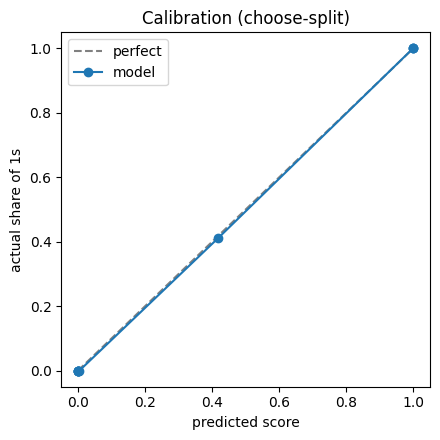

Saved F_results.json, F_top_words.csv, F_errors.csv, F_calibration.png in /content/drive/MyDrive/CSC3104_money_otp/processed


In [ ]:
# ---- F6: worst mistakes
err_sets = [gold.assign(set="SG gold", sentence=gold["text"])[["set", "sentence", "label", "score", "keyword", "category"]]]
if ftc_eval is not None:
    err_sets.append(ftc_eval.assign(set="FTC", category=ftc_eval["topic"])[["set", "sentence", "label", "score", "keyword", "category"]])
errs = pd.concat(err_sets)
errs["error"] = (errs["score"] - errs["label"]).abs()
worst = errs[errs["error"] >= 0.5].sort_values("error", ascending=False).head(20)
print("F6. Worst mistakes")
with pd.option_context("display.max_colwidth", 120):
    display(worst)
worst.to_csv(out("F_errors.csv"), index=False)

# ---- F7: calibration plot (choose-split was not used to fit the calibration)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
if os.path.exists(out("E_choose_split.csv")):
    cs = pd.read_csv(out("E_choose_split.csv"))
    frac, mean_p = calibration_curve(cs["label"], cs["score"], n_bins=10, strategy="quantile")
    plt.figure(figsize=(4.5, 4.5))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
    plt.plot(mean_p, frac, "o-", label="model")
    plt.xlabel("predicted score"); plt.ylabel("actual share of 1s"); plt.title("Calibration (choose-split)")
    plt.legend(); plt.tight_layout()
    plt.savefig(out("F_calibration.png"), dpi=150)
    plt.show()

json.dump(results_all, open(out("F_results.json"), "w"), indent=2, default=str)
print("Saved F_results.json, F_top_words.csv, F_errors.csv, F_calibration.png in", OUT_DIR)

In [ ]:
# ---- G: test the model on test_set_binary_classifier.csv
TEST_FILE = "test_set_binary_classifier.csv"   # put it next to the notebook or in the Drive folder
TEST_TEXT_COL = None      # e.g. "text"  (None = auto-detect)
TEST_LABEL_COL = None     # e.g. "label" (None = auto-detect)

TEXT_NAMES = ["text", "sentence", "utterance", "message", "content", "transcript", "input"]
LABEL_NAMES = ["label", "labels", "target", "y", "class", "gold", "is_money", "money"]
POS = {"1", "1.0", "true", "yes", "y", "positive", "pos", "money", "otp", "money_otp"}
NEG = {"0", "0.0", "false", "no", "n", "negative", "neg", "none", "other", "not_money"}

def to_binary(v):
    s = str(v).strip().lower()
    return 1 if s in POS else 0 if s in NEG else np.nan

raw_test = pd.read_csv(find_or_upload(TEST_FILE))
print(f"G. {TEST_FILE}: {len(raw_test)} rows, columns = {list(raw_test.columns)}")

# ---- find the text and label columns
tcol = TEST_TEXT_COL or next((c for c in raw_test.columns if c.lower() in TEXT_NAMES), None)
if tcol is None:
    strs = [c for c in raw_test.columns if not pd.api.types.is_numeric_dtype(raw_test[c])]
    tcol = max(strs, key=lambda c: raw_test[c].astype(str).str.len().mean())
lcol = TEST_LABEL_COL or next((c for c in raw_test.columns if c.lower() in LABEL_NAMES), None)
if lcol is None:
    lcol = next((c for c in raw_test.columns if c != tcol and raw_test[c].map(to_binary).notna().all()), None)
if lcol is None:
    raise ValueError(f"Could not find a 0/1 label column in {list(raw_test.columns)}: set TEST_LABEL_COL")
print(f"Using text column '{tcol}' and label column '{lcol}'")

t = raw_test.copy()
t["text"] = t[tcol].astype(str).str.strip()
t["label"] = t[lcol].map(to_binary)
bad = int(t["label"].isna().sum())
if bad:
    print(f"Warning: {bad} rows with a label that is not 0/1/yes/no etc. are left out. Examples:",
          raw_test.loc[t["label"].isna(), lcol].unique()[:5])
t = t[t["label"].notna() & (t["text"].str.len() > 0)].copy()
t["label"] = t["label"].astype(int)
t["clean"] = t["text"].map(clean_text)
n0 = len(t)
t = t.drop_duplicates("clean").reset_index(drop=True)
if len(t) < n0:
    print(f"Removed {n0 - len(t)} duplicate sentences")
print(f"{len(t)} test sentences: {int(t['label'].sum())} ones, {int((1 - t['label']).sum())} zeros")

# ---- leakage check: is any test sentence (almost) in the training data?
t["seen_in_training"] = False
if "train" in globals():
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text_clean"])
    sim = (vec.transform(t["clean"]) @ vec.transform(train["text_clean"]).T).max(axis=1).toarray().ravel()
    t["seen_in_training"] = sim >= NEAR_DUP_THRESHOLD
    print(f"Leakage check: {int(t['seen_in_training'].sum())} test sentences are >= {NEAR_DUP_THRESHOLD} similar to training data")
else:
    print("Leakage check skipped (training table not in memory: run Part C in this session to enable it)")

# ---- score
t["score"] = model.predict_proba(t["text"])
t["keyword"] = keyword_pred(t["text"])
t["pred"] = (t["score"] >= THRESHOLD).astype(int)

print("\nG1. Overall (model vs keyword list)")
g_table = compare(t["label"], t["score"], t["keyword"], "Test set")
g_table["pr_auc"] = g_table["pr_auc"].fillna("-")
display(g_table)
if t["seen_in_training"].any():
    u = t[~t["seen_in_training"]]
    print(f"Same table without the {int(t['seen_in_training'].sum())} sentences seen in training ({len(u)} left):")
    display(compare(u["label"], u["score"], u["keyword"], "Test set (unseen only)").fillna("-"))

# ---- confusion matrix
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(t["label"], t["pred"], labels=[0, 1]).ravel()
print(f"\nG2. Confusion matrix at threshold {THRESHOLD}")
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"]))
print(f"accuracy = {(tp + tn) / len(t):.3f}   false-alarm rate (0s scored as 1) = {fp / max(fp + tn, 1):.3f}   "
      f"miss rate (1s scored as 0) = {fn / max(fn + tp, 1):.3f}")

# ---- per category / per call type (only if the file has them)
for grp in [c for c in ("category", "call_type") if c in t.columns]:
    pc = t.groupby(grp).agg(n=("label", "size"), label_mean=("label", "mean"), mean_score=("score", "mean"))
    pc["model_correct_pct"] = t.assign(ok=(t["pred"] == t["label"])).groupby(grp)["ok"].mean().mul(100).round(0)
    pc["keyword_correct_pct"] = t.assign(ok=(t["keyword"] == t["label"])).groupby(grp)["ok"].mean().mul(100).round(0)
    print(f"\nG3. Per {grp}")
    display(pc.round(3).sort_values("model_correct_pct"))

# ---- threshold sweep
sweep = pd.DataFrame([{"threshold": th, **metrics_at(t["label"], t["score"], th)} for th in (0.3, 0.4, 0.5, 0.6, 0.7)])
print("\nG4. Threshold sweep")
display(sweep)

# ---- mistakes
errs_g = t[t["pred"] != t["label"]].assign(error=lambda d: (d["score"] - d["label"]).abs()).sort_values("error", ascending=False)
show = [c for c in ("text", "label", "score", "keyword", "category", "call_type") if c in errs_g.columns]
with pd.option_context("display.max_colwidth", 110):
    print(f"\nG5. False alarms (label 0, scored high): {int(fp)} total, worst 15")
    display(errs_g[errs_g["label"] == 0][show].head(15))
    print(f"G5. Misses (label 1, scored low): {int(fn)} total, worst 15")
    display(errs_g[errs_g["label"] == 1][show].head(15))

t.drop(columns=["clean"]).to_csv(out("G_test_set_scored.csv"), index=False)
errs_g[show].to_csv(out("G_test_set_errors.csv"), index=False)
results_all["test_set"] = g_table.to_dict("records")
json.dump(results_all, open(out("F_results.json"), "w"), indent=2, default=str)
print("\nSaved G_test_set_scored.csv and G_test_set_errors.csv in", OUT_DIR)

G. test_set_binary_classifier.csv: 200 rows, columns = ['sentence_id', 'text', 'label', 'call_type', 'category']
Using text column 'text' and label column 'label'
200 test sentences: 100 ones, 100 zeros
Leakage check: 0 test sentences are >= 0.9 similar to training data

G1. Overall (model vs keyword list)


,set,method,precision,recall,f1,pr_auc
0,Test set,model @0.5,0.909,0.90,0.905,0.98
1,Test set,model @0.6,0.928,0.90,0.914,-
2,Test set,keyword list,0.927,0.89,0.908,-



G2. Confusion matrix at threshold 0.5


,predicted 0,predicted 1
actual 0,91,9
actual 1,10,90


accuracy = 0.905   false-alarm rate (0s scored as 1) = 0.090   miss rate (1s scored as 0) = 0.100

G3. Per category


,n,label_mean,mean_score,model_correct_pct,keyword_correct_pct
category,,,,,
hard_one,10,1.0,0.281,10.0,40.0
hard_zero,15,0.0,0.170,80.0,93.0
word_sense,25,0.0,0.147,88.0,84.0
otp_lookalike,10,0.0,0.144,90.0,100.0
otp_request,15,1.0,0.906,93.0,87.0
impersonation_only,15,0.0,0.088,93.0,87.0
urgency_only,15,0.0,0.074,93.0,100.0
everyday,20,0.0,0.006,100.0,100.0
money_mention,30,1.0,0.996,100.0,97.0


... (5 outputs left out)

,text,label,score,keyword,category,call_type
132,You should pay heed to the doctor's advice and get sufficient rest.,0,0.974884,1,word_sense,legit
144,You must pay tribute to the pioneers who built this organization.,0,0.917162,1,word_sense,legit
199,The bill was passed in parliament after a lengthy debate among members.,0,0.871199,0,hard_zero,legit
148,Please respond within ten minutes or your registered account will be suspended.,0,0.861192,0,urgency_only,scam
173,This is OCBC security division calling regarding your online banking profile status.,0,0.815780,1,impersonation_only,scam
140,He paid a compliment to his colleague for her excellent project presentation.,0,0.697239,1,word_sense,legit
191,The museum displays a rare collection of priceless historical artifacts and paintings.,0,0.682325,0,hard_zero,legit
187,We need to invest more time and effort into training our junior employees.,0,0.567917,1,hard_zero,legit
180,The verification PIN for unlocking your office door access lock is 4589.,0,0.514501,0,otp_lookalike,legit


G5. Misses (label 1, scored low): 10 total, worst 15


,text,label,score,keyword,category,call_type
90,Make sure you settle what you owe before five o'clock this evening.,1,0.000365,0,hard_one,scam
96,That fancy dinner at Marina Bay Sands really burned a huge hole in my pocket.,1,0.002300,0,hard_one,legit
3,"Sir, I need you to authorize the login push notification on your Singpass app right now.",1,0.033683,0,otp_request,scam
94,You need to clear your outstanding dues with us by the end of today.,1,0.070564,0,hard_one,scam
97,Make sure you balance your ledger before submitting the final financial statements.,1,0.222692,0,hard_one,legit
95,I had to cough up a few pineapple notes for the car repairs.,1,0.260582,0,hard_one,legit
93,How much damage did you do at the Great Singapore Sale today?,1,0.265155,0,hard_one,legit
91,Buying that new branded handbag is going to set you back eighty bucks.,1,0.284979,1,hard_one,legit
98,He asked me to foot the entire bill for the team lunch yesterday.,1,0.333454,1,hard_one,legit
92,The red packet my grandmother gave me had a hundred in it inside.,1,0.367908,1,hard_one,legit



Saved G_test_set_scored.csv and G_test_set_errors.csv in /content/drive/MyDrive/CSC3104_money_otp/processed
